# TCGA: biological controls and candidate relationships


TCGA has no complete causal ground truth. These results measure agreement with selected biological references, seed support and threshold sensitivity; candidate edges remain hypotheses.


In [1]:
from pathlib import Path
import sys, os, json
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "experiments/run_model.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from inside the repository.")
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))
sys.path[:0] = [str(ROOT / "analysis"), str(ROOT / "experiments")]
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import final_visualization as fv
import result_tables as th
fv.apply_style()
th.ensure_output_dirs("tcga")


## Controls and internal-threshold sensitivity


In [2]:
from glioma_analysis import (
    build_internal_threshold_graphs,
    build_model_graphs,
    import_existing_analyses,
    internal_threshold_sensitivity_summary,
    load_glioma_results,
)
from matplotlib.colors import LinearSegmentedColormap

tcga_models = ("PRISM", "GRASP", "AVICI", "PC", "GES", "GOLEM")
glioma = load_glioma_results(ROOT, tcga_models)
tcga_graphs = build_model_graphs(glioma, tcga_models, min_rate=0.8, edge_mode="directed")
primary_graphs = tcga_graphs["PRISM"]
contexts = ["Full cohort", "Astrocytoma", "Glioblastoma", "Oligodendroglioma"]
joint_datasets = [
    "tcga_mut_expr70",
    "tcga_mut_expr70__astro",
    "tcga_mut_expr70__gbm",
    "tcga_mut_expr70__oligo",
]
phased_scorer = import_existing_analyses(glioma)["phased_scoring"]
reference_genes = sorted({label.split("_", 1)[0] for label in glioma.labels["tcga_mut_expr70"]})
relations = phased_scorer.load_relations(reference_genes)
control_edges = sorted({(row["source"], row["target"]) for row in relations})

def edge_rate(graph, source, target):
    rows = graph.loc[(graph.source == source) & (graph.target == target)]
    return float(rows.rate.max()) if not rows.empty else 0.0

rates = np.zeros((len(control_edges), len(joint_datasets)))
support = np.zeros_like(rates, dtype=int)
for i, (source, target) in enumerate(control_edges):
    for j, dataset in enumerate(joint_datasets):
        rates[i, j] = edge_rate(primary_graphs[dataset], source, target)
        support[i, j] = sum(
            (
                edge_rate(graphs[dataset], source, target) >= 0.8
                for model, graphs in tcga_graphs.items()
                if model != "PRISM" and dataset in graphs
            )
        )

def clean_variable(value):
    return value.replace("_expr_log2tpm", " RNA").replace("_mut", " mut.")

labels = [
    f"{clean_variable(source)} → {clean_variable(target)}" for source, target in control_edges
]


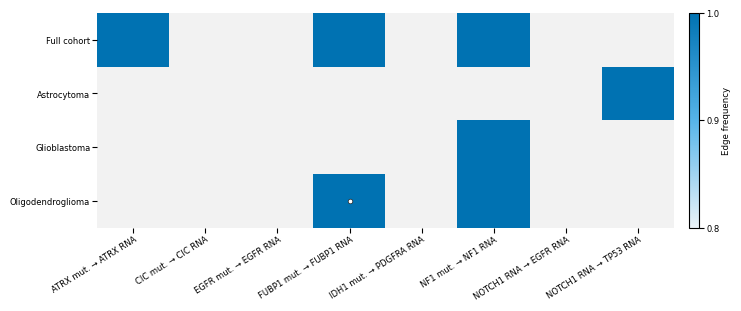

In [3]:
cmap = LinearSegmentedColormap.from_list("control_blue", ["#EAF3F8", "#56B4E9", "#0072B2"])
cmap.set_bad("#F2F2F2")
fig_controls, ax = plt.subplots(figsize=(7.3, 3.0), constrained_layout=True)
masked = np.ma.masked_less(rates.T, 0.8)
image = ax.imshow(masked, cmap=cmap, vmin=0.8, vmax=1.0, aspect="auto")
ax.set_xticks(range(len(labels)), labels, rotation=32, ha="right", rotation_mode="anchor")
ax.set_yticks(range(4), contexts)
ax.tick_params(axis="both", labelsize=6, pad=1.5)
for i, j in zip(*np.where((rates >= 0.8) & (support >= 2))):
    ax.scatter(i, j, s=11, facecolor="white", edgecolor="#222222", linewidth=0.5)
for spine in ax.spines.values():
    spine.set_visible(False)
colorbar = fig_controls.colorbar(image, ax=ax, fraction=0.05, pad=0.025)
colorbar.set_label("Edge frequency", fontsize=6.2, labelpad=2)
colorbar.set_ticks([0.8, 0.9, 1.0])
colorbar.ax.tick_params(labelsize=6, pad=1.5)
controls_pdf = th.save_pdf(fig_controls, "tcga_biological_controls.pdf")
display(fig_controls)
plt.close(fig_controls)
thresholds = (0.1, 0.125, 0.15, 0.2)
matrix_roots = (
    ROOT / "results/tcga/arms_results",
    ROOT / "results/tcga/arms_results_subtypes",
)
threshold_graphs, _ = build_internal_threshold_graphs(
    glioma,
    thresholds=thresholds,
    consensus_rate=0.8,
    model="PRISM",
    matrix_roots=matrix_roots,
)
_, reference_detail = internal_threshold_sensitivity_summary(glioma, threshold_graphs, phase=1)

def edge_set(frame):
    return set(zip(frame.source, frame.target))

rows = []
for threshold in thresholds:
    expr = edge_set(threshold_graphs[threshold]["tcga_expr35"])
    joint_frame = threshold_graphs[threshold]["tcga_mut_expr70"]
    joint_expr = {
        (s, t)
        for s, t in edge_set(joint_frame)
        if not s.endswith("_mut") and (not t.endswith("_mut"))
    }
    rows.append(
        {
            "internal_threshold": threshold,
            "expression_only": len(expr),
            "mutation_expression": len(joint_expr),
        }
    )


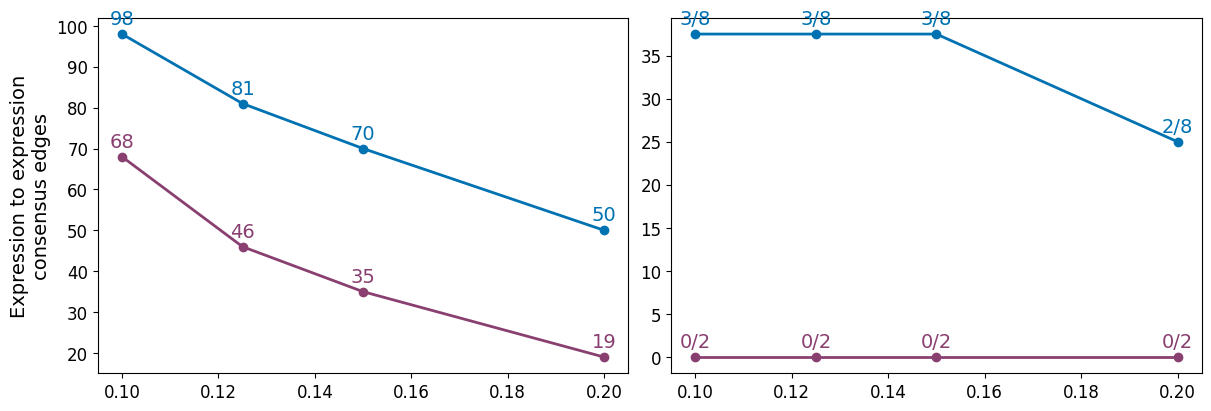

In [4]:
threshold_edges = pd.DataFrame(rows)
reference_summary = (
    reference_detail[reference_detail.dataset.isin(("tcga_expr35", "tcga_mut_expr70"))]
    .groupby(["internal_threshold", "dataset"], as_index=False)
    .agg(
        applicable=("status", "size"),
        recovered=("status", lambda x: x.eq("direta_sentido_certo").sum()),
    )
)
reference_summary["recall"] = 100 * reference_summary.recovered / reference_summary.applicable
fig_threshold, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for column, label, color in (
    ("expression_only", "Expression-only", "#8A3F71"),
    ("mutation_expression", "Mutation-expression", "#0072B2"),
):
    axes[0].plot(
        threshold_edges.internal_threshold,
        threshold_edges[column],
        marker="o",
        color=color,
        linewidth=2,
        label=label,
    )
    for row in threshold_edges.itertuples(index=False):
        axes[0].annotate(
            str(int(getattr(row, column))),
            (row.internal_threshold, getattr(row, column)),
            xytext=(0, 7),
            textcoords="offset points",
            ha="center",
            color=color,
        )
axes[0].set_ylabel("Expression to expression\nconsensus edges")
for dataset, label, color in (
    ("tcga_expr35", "Expression-only", "#8A3F71"),
    ("tcga_mut_expr70", "Mutation-expression", "#0072B2"),
):
    part = reference_summary.loc[reference_summary.dataset.eq(dataset)]
    axes[1].plot(
        part.internal_threshold,
        part.recall,
        marker="o",
        color=color,
        linewidth=2,
        label=label,
    )
    for row in part.itertuples(index=False):
        axes[1].annotate(
            f"{int(row.recovered)}/{int(row.applicable)}",
            (row.internal_threshold, row.recall),
            xytext=(0, 7),
            textcoords="offset points",
            ha="center",
            color=color,
        )


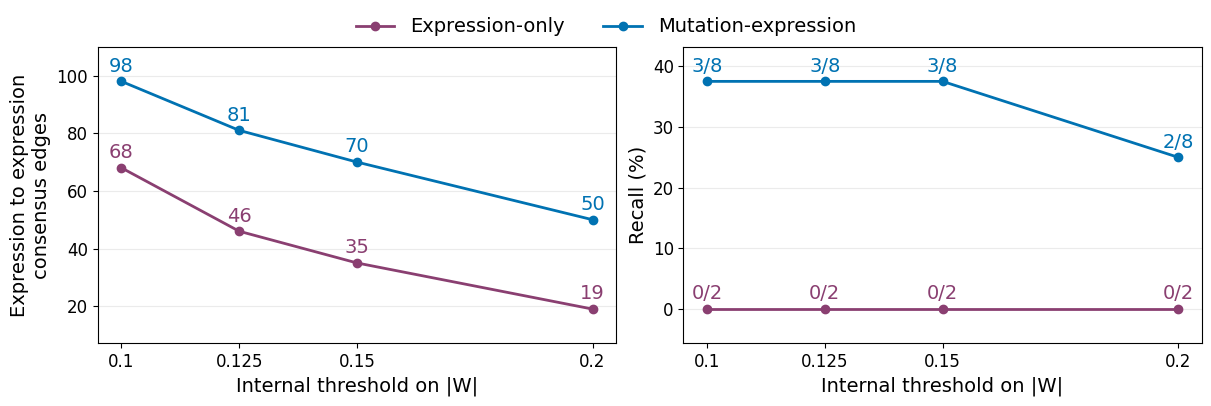

In [5]:
axes[1].set_ylabel("Recall (%)")
handles, labels = axes[0].get_legend_handles_labels()
fig_threshold.legend(handles, labels, loc="outside upper center", ncol=2, frameon=False)
for axis in axes:
    axis.margins(y=0.15)
    axis.set_xlabel("Internal threshold on |W|")
    axis.set_xticks(thresholds)
    axis.set_xticklabels([f"{value:g}" for value in thresholds])
    axis.grid(axis="y", alpha=0.25)
threshold_pdf = th.save_pdf(fig_threshold, "tcga_prism_internal_threshold_sensitivity.pdf")
display(fig_threshold)
plt.close(fig_threshold)


## Candidate relationships


In [6]:
from select_tcga_high_confidence_edges import (
    EXPRESSION_FAMILY,
    JOINT_FAMILY,
    family_candidates,
    reference_edges,
    short_name,
)

expression_candidates = family_candidates(tcga_graphs, EXPRESSION_FAMILY, "expr->expr")
joint_candidates = family_candidates(tcga_graphs, JOINT_FAMILY, "expr->expr")
known = reference_edges()
candidate_rows = []
for edge in sorted(set(expression_candidates) & set(joint_candidates)):
    if edge in known or (edge[1], edge[0]) in known:
        continue
    supporting = sorted(
        set(expression_candidates[edge]["supporting_methods"])
        | set(joint_candidates[edge]["supporting_methods"])
    )
    candidate_rows.append(
        {
            "Candidate relationship": f"{short_name(edge[0])} -> {short_name(edge[1])}",
            "Expr.": f"{expression_candidates[edge]['n_contexts']}/4",
            "Joint": f"{joint_candidates[edge]['n_contexts']}/4",
            "Min. seed support": min(
                expression_candidates[edge]["minimum_seed_rate"],
                joint_candidates[edge]["minimum_seed_rate"],
            ),
            "Supporting methods": ", ".join((th.model_label(model) for model in supporting)),
        }
    )
candidate_table = pd.DataFrame(candidate_rows).sort_values(
    ["Expr.", "Joint", "Min. seed support"], ascending=False
)
display(candidate_table)


,Candidate relationship,Expr.,Joint,Min. seed support,Supporting methods
0,SMARCA4 -> TP53,3/4,3/4,1.0,GRaSP


## Representation overlap and seed-consensus sensitivity

Internal weight thresholds and agreement across model seeds are varied separately. The full-cohort comparison distinguishes all directed edges from expression-to-expression edges.


In [7]:

expression = edge_set(threshold_graphs[.1]["tcga_expr35"])
joint = edge_set(threshold_graphs[.1]["tcga_mut_expr70"])
joint_expression = {(s, t) for s, t in joint if not s.endswith("_mut") and not t.endswith("_mut")}
overlap = pd.DataFrame([dict(expression_edges=len(expression), joint_total_edges=len(joint),
                             joint_expression_edges=len(joint_expression),
                             shared_direction=len(expression & joint_expression),
                             expression_only=len(expression - joint_expression),
                             joint_only=len(joint_expression - expression),
                             net_expression_edges=len(joint_expression) - len(expression))])
display(overlap)
selected = (set(expression_candidates) & set(joint_candidates)) - known
selected = {edge for edge in selected if (edge[1], edge[0]) not in known}
strict_graphs, _ = build_internal_threshold_graphs(glioma, thresholds=(.1,), consensus_rate=1.0,
                                                  model="PRISM", matrix_roots=matrix_roots)
_, strict_detail = internal_threshold_sensitivity_summary(glioma, strict_graphs, phase=1)
rows = []
for agreement, graphs, detail in ((.8, threshold_graphs[.1], reference_detail.loc[reference_detail.internal_threshold.eq(.1)]),
                                  (1.0, strict_graphs[.1], strict_detail)):
    for dataset in ("tcga_expr35", "tcga_mut_expr70"):
        edges = edge_set(graphs[dataset])
        expression_edges = {(s, t) for s, t in edges if not s.endswith("_mut") and not t.endswith("_mut")}
        references = detail.loc[detail.dataset.eq(dataset)]
        rows.append(dict(seed_agreement=agreement, dataset=dataset, total_edges=len(edges),
                         expression_edges=len(expression_edges), candidates_retained=len(selected & edges),
                         references_recovered=int(references.status.eq("direta_sentido_certo").sum()),
                         references_applicable=len(references)))
consensus = pd.DataFrame(rows)
display(consensus)

retention = []
for threshold, contexts in threshold_graphs.items():
    for dataset, graph in contexts.items():
        if dataset.startswith("tcga_mut35"):
            continue
        edges = edge_set(graph)
        for source, target in sorted(selected):
            retention.append(dict(relationship=f"{short_name(source)} -> {short_name(target)}", dataset=dataset,
                                  internal_threshold=threshold, present=(source, target) in edges))
retention = pd.DataFrame(retention)
display(retention.groupby(["relationship", "internal_threshold"]).present.sum().unstack("internal_threshold"))


,expression_edges,joint_total_edges,joint_expression_edges,shared_direction,expression_only,joint_only,net_expression_edges
0,68,131,98,56,12,42,30


,seed_agreement,dataset,total_edges,expression_edges,candidates_retained,references_recovered,references_applicable
0,0.8,tcga_expr35,68,68,1,0,2
1,0.8,tcga_mut_expr70,131,98,1,3,8
2,1.0,tcga_expr35,68,68,1,0,2
3,1.0,tcga_mut_expr70,122,92,1,3,8


internal_threshold,0.100,0.125,0.150,0.200
relationship,,,,
SMARCA4 -> TP53,6,6,5,3
